In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split


In [2]:
df = pd.read_csv("Iris.csv")

display=(df.head())
print("Dataset shape:", df.shape)
print("\nSpecies counts:")
print(df["Species"].value_counts())

Dataset shape: (150, 6)

Species counts:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [3]:
X = df.drop(columns=["Id", "Species"])
y = df["Species"]

print("Feature columns:", X.columns.tolist())
print("Target classes:", y.unique())

Feature columns: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Target classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 120
Testing rows: 30


In [5]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)

print("Random Forest model trained.")

Random Forest model trained.


In [6]:
y_pred = model.predict(X_test)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test.iloc[:10].to_list())

First 10 predictions: ['Iris-setosa' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor']
First 10 actual labels: ['Iris-setosa', 'Iris-virginica', 'Iris-versicolor', 'Iris-versicolor', 'Iris-setosa', 'Iris-versicolor', 'Iris-setosa', 'Iris-setosa', 'Iris-virginica', 'Iris-versicolor']


In [7]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=model.classes_, zero_division=0))

Accuracy: 90.00%

Classification report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



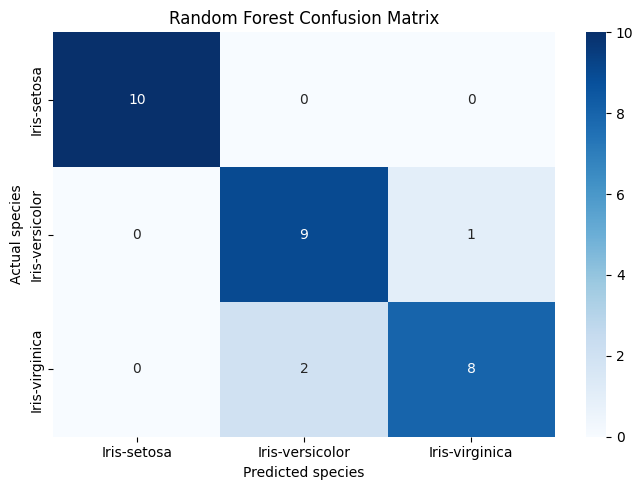

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

Feature importance (%):


,Importance (%)
PetalWidthCm,43.72
PetalLengthCm,43.15
SepalLengthCm,11.63
SepalWidthCm,1.50


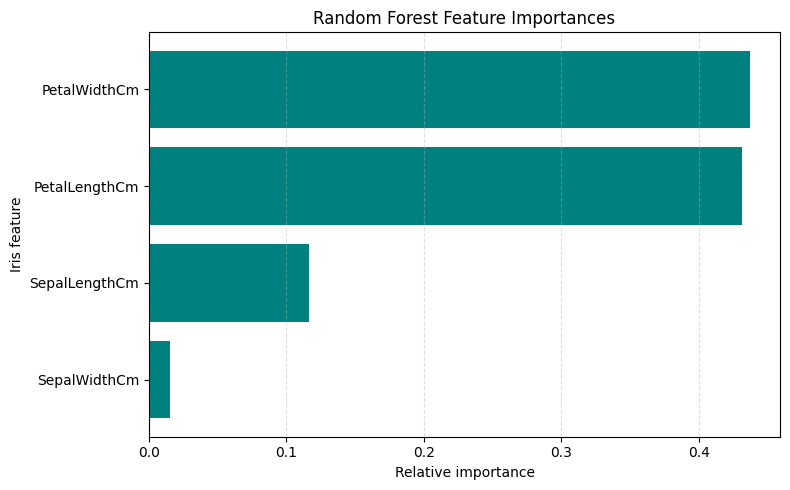

In [9]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

print("Feature importance (%):")
display(
    (feature_importance.sort_values(ascending=False) * 100)
    .round(2)
    .rename("Importance (%)")
    .to_frame()
)

plt.figure(figsize=(8, 5))
plt.barh(feature_importance.index, feature_importance.values, color="teal")
plt.xlabel("Relative importance")
plt.ylabel("Iris feature")
plt.title("Random Forest Feature Importances")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [10]:
new_flower = pd.DataFrame({
    "SepalLengthCm": [5.9],
    "SepalWidthCm": [2.8],
    "PetalLengthCm": [4.7],
    "PetalWidthCm": [1.2]
})

predicted_species = model.predict(new_flower)

print("New flower measurements:")
display(new_flower)
print("Predicted species:", predicted_species[0])

New flower measurements:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.9,2.8,4.7,1.2


Predicted species: Iris-versicolor
